# Comparación de modelos — Fase 5

Comparación académica exploratoria con protocolo v2 congelado. Solo entrenamiento y validación; prueba reservada. Se conserva la organización y narrativa de los proyectos anteriores del curso.

## 1. Contrato temporal y preparación

Se revisaron fase 4.2, fase 4 histórica, splitting.py, baseline.py y preparación. El baseline activo es v2. Entrenamiento: 54.164 (42,60% cancelaciones); validación: 18.097 (42,84%). Cortes 01/07/2016 y 01/01/2017; resultado fechado + un día. No se cambian IDs ni reglas. Cierre retrospectivo supuesto 01/12/2018, sin cierre PMS acreditado.

### Contexto metodológico

La comparación de logística, árbol, Random Forest, XGBoost y LightGBM corresponde a validación v2. Compartir particiones y predictores hace comparable ese experimento interno, pero no lo convierte en una comparación directa con v3. Las métricas globales de scores y las decisiones a 0,5 responden preguntas distintas.

**Qué se hace y por qué.** Resolver rutas e importar la comparación de modelos del protocolo histórico v2.



In [1]:
# Resolver rutas e importar la comparación de modelos del protocolo histórico v2.
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "src").is_dir(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.comparison import run_comparison


## 2. Configuraciones prefijadas

Logística existente C=1, lbfgs, max_iter=2000. Árbol profundidad 8 y hoja mínima 20. Bosque 200 árboles y hoja mínima 5. XGBoost 300 árboles, profundidad 4, tasa 0,05 y submuestreo 0,8 de filas/columnas. LightGBM 300 árboles, 31 hojas, tasa 0,05 y hoja mínima 20. Semillas 42, cuatro hilos en ensembles. Sin búsquedas, early stopping ni ponderación de clases.

Pipelines independientes: medianas y one-hot ignorando categorías desconocidas; solo logística escala. Todas las estadísticas se aprenden de entrenamiento. Un bloque desconocido queda a cero, sin aprender su efecto. Umbral común 0,5: no presupone calibración comparable.

**Qué se hace y por qué.** Comparar cinco configuraciones iniciales sobre la misma validación v2.



In [2]:
# Comparar cinco configuraciones iniciales sobre la misma validación v2.
metrics, verification, predictions = run_comparison(ROOT)
display(metrics.round(6))
print("Baseline v2 reproducido:", verification["baseline_v2_reproducido"])
print("Advertencias de fit:", verification["advertencias_fit"])

Entrenando: regresion_logistica


Entrenando: arbol_decision


Entrenando: random_forest


Entrenando: xgboost


Entrenando: lightgbm


,modelo,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,fit_seconds,predict_seconds
0,regresion_logistica,0.747085,0.807633,0.537727,0.645606,0.820718,0.807536,9351,993,3584,4169,0.267440,0.018964
1,arbol_decision,0.715809,0.853276,0.406552,0.550712,0.786223,0.752406,9802,542,4601,3152,0.230861,0.017849
2,random_forest,0.738631,0.883532,0.449116,0.595519,0.841311,0.823312,9885,459,4271,3482,4.567623,0.082109
3,xgboost,0.765707,0.862988,0.538630,0.663278,0.858927,0.842275,9681,663,3577,4176,0.459084,0.038361
4,lightgbm,0.745925,0.863731,0.483168,0.619686,0.848655,0.830643,9753,591,4007,3746,0.381800,0.067237


Baseline v2 reproducido: True
Advertencias de fit: {'regresion_logistica': [], 'arbol_decision': [], 'random_forest': [], 'xgboost': [], 'lightgbm': []}


## 3. Discriminación y errores

Average Precision resume precision-recall sin integración trapezoidal; su referencia constante es la prevalencia de validación (0,4284). ROC-AUC y AP evalúan ordenación; precision, recall y F1 usan 0,5. Las probabilidades no están calibradas por esta comparación.

**Qué se hace y por qué.** Mostrar ROC, precision-recall y matrices de aquella población.



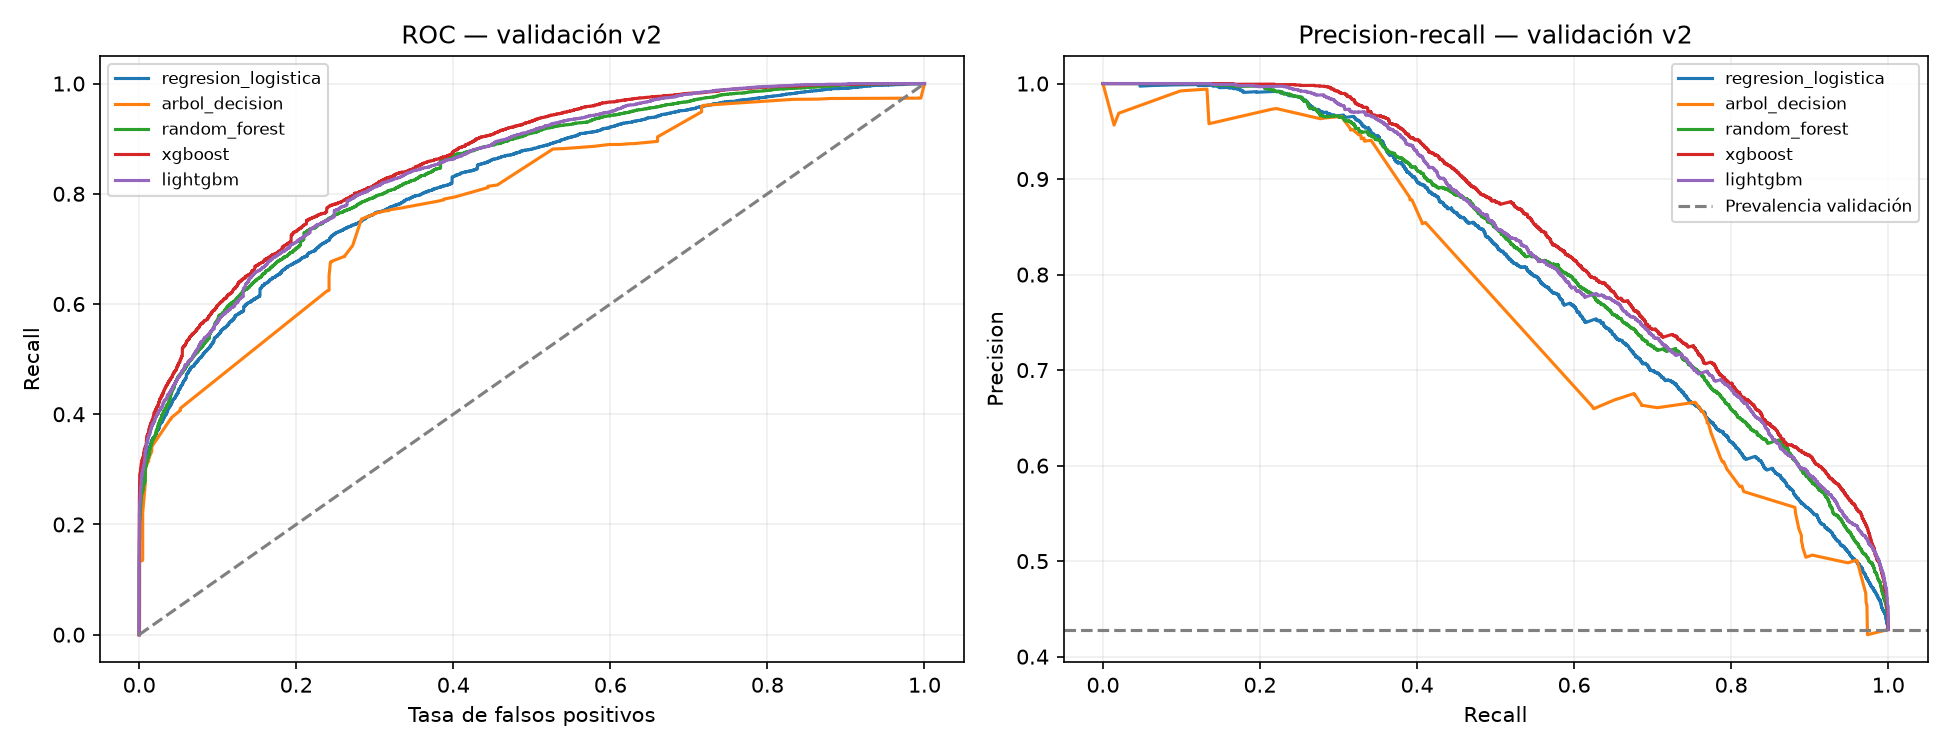

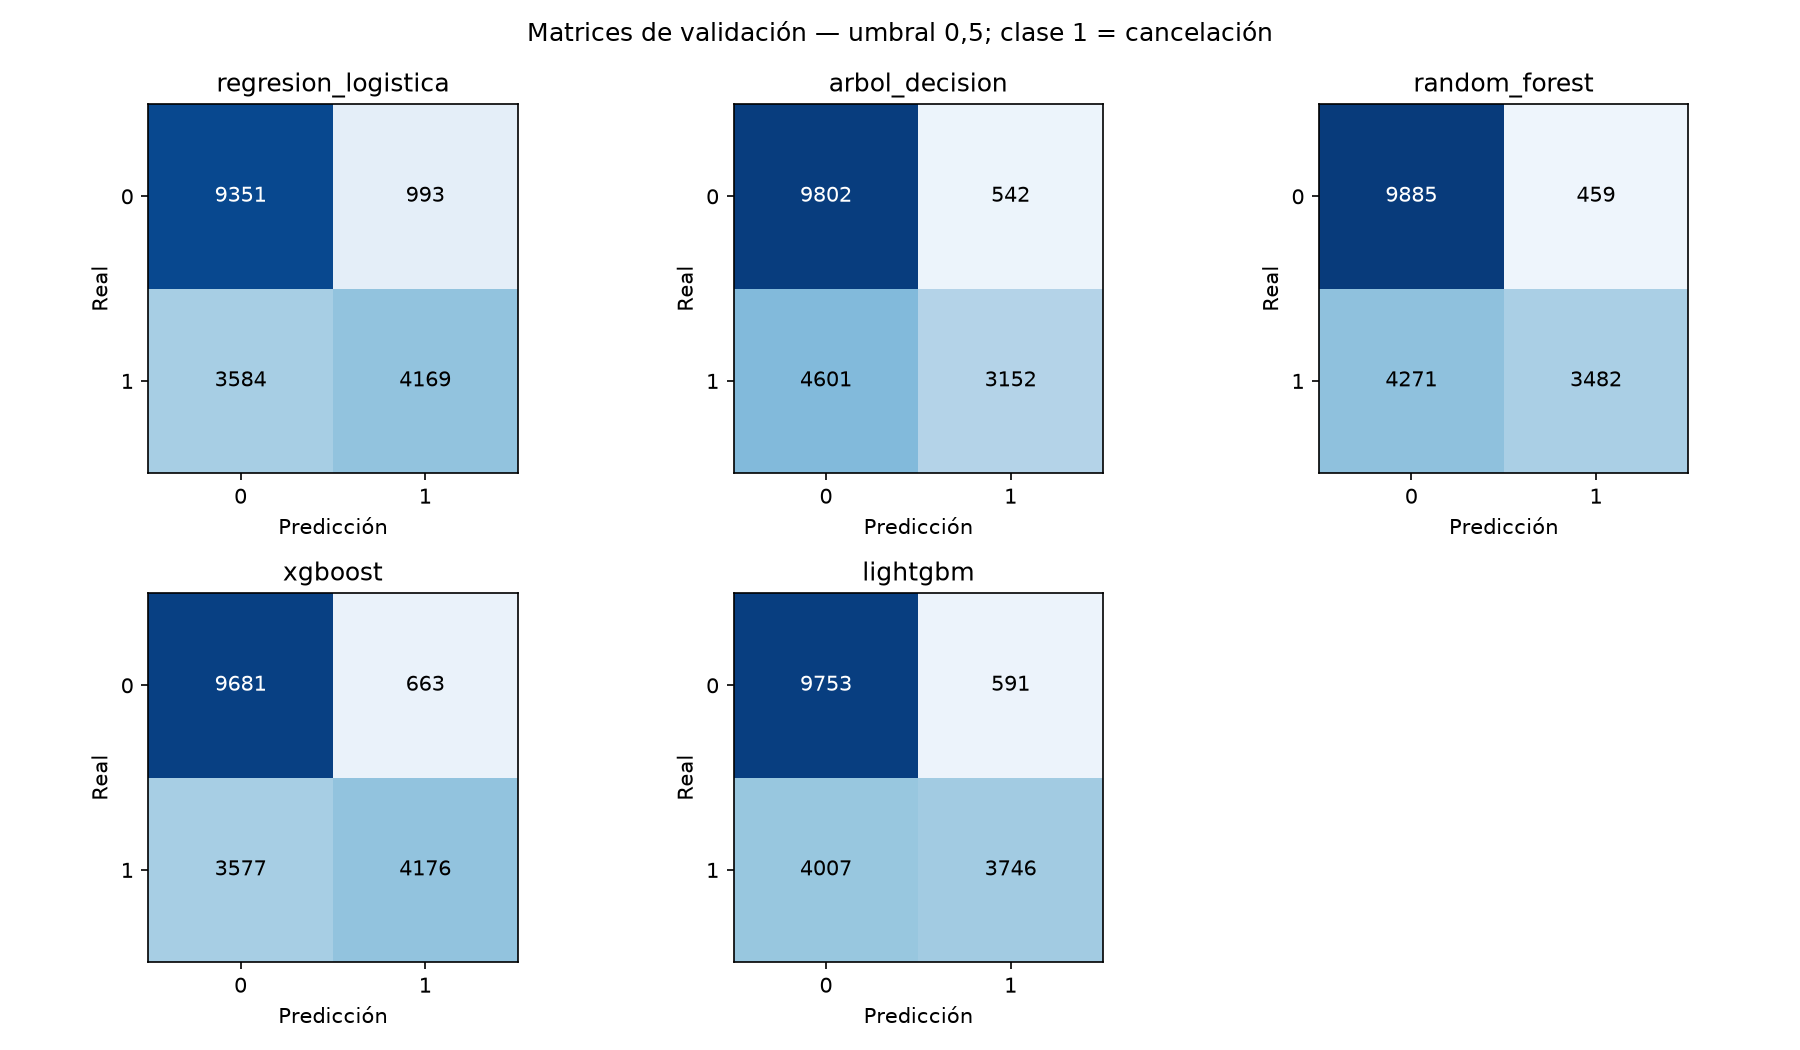

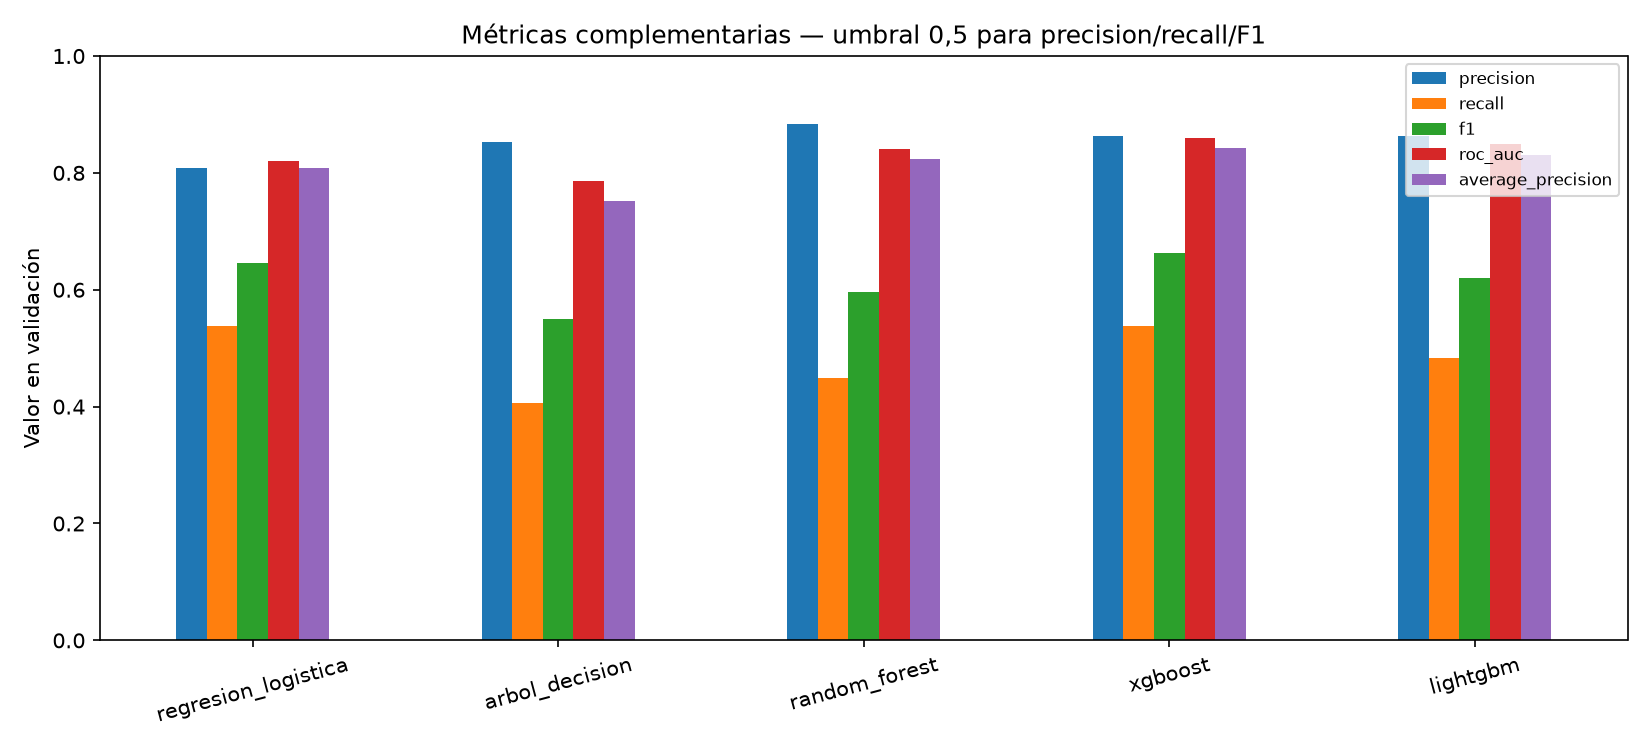

In [3]:
# Mostrar ROC, precision-recall y matrices de aquella población.
for name in ["curvas", "matrices", "metricas"]:
    display(Image(filename=str(ROOT / f"reports/figures/comparacion_5_{name}.png")))

## 4. Alcance de las conclusiones

Consultar el informe fase_5_comparacion_modelos.md para la comparación y los dos candidatos. Falsos negativos: riesgo de cancelación no anticipado; falsos positivos: seguimiento innecesario y posible molestia al cliente. No hay costes económicos medidos.

La disponibilidad histórica de los 14 campos no está acreditada. La reserva es un proxy y las etiquetas dependen del último estado, no de su primera disponibilidad. Permanecen 20.564 pendientes, sesgo hacia menor antelación, selección por resultados disponibles y duplicados conservados. El EDA vio todo el archivo. No es validación de producción, ni se selecciona modelo o umbral definitivo. Fin exclusivo de fase 5.

## Resultados y recomendación

XGBoost alcanza ROC-AUC 0,8589 y AP 0,8423: frente a logística reduce 330 falsos positivos y siete falsos negativos. LightGBM es segundo en discriminación (ROC-AUC 0,8487; AP 0,8306), pero su recall 48,32% queda por debajo del 53,77% de logística. Bosque tiene la mayor precision (88,35%) y solo 459 falsas alarmas, pero pierde más cancelaciones. Árbol no supera la referencia en discriminación.

Se recomiendan XGBoost y LightGBM como candidatos, manteniendo logística como referencia sencilla. No son modelos definitivos. Para fase 6 se propone una optimización limitada con validación temporal interna y requisitos de negocio, tras autorización. La complejidad no resuelve las limitaciones de datos.

**Qué se hace y por qué.** Verificar la comparación histórica y la ausencia de cambios en archivos protegidos.



In [4]:
# Verificar la comparación histórica y la ausencia de cambios en archivos protegidos.
import io, unittest
# Seleccionar las pruebas de esta llamada; los conjuntos históricos pueden incluir entrenamientos.
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
log = io.StringIO()
# Ejecutar la batería indicada y conservar su salida; comprobar qué pruebas admite esta fase.
result = unittest.TextTestRunner(stream=log, verbosity=1).run(suite)
print(log.getvalue())
assert result.wasSuccessful()
print("Pruebas superadas:", result.testsRun)

....................
----------------------------------------------------------------------
Ran 20 tests in 0.435s

OK

Pruebas superadas: 20
